# Notebook 19 — Structured Evidence Information Extraction & Field-Level Evaluation

**Project:** AI-Powered Student Achievement Intelligence Platform  
**Member:** Member 1 — NLP & Semantic Intelligence Engineer  
**Stage:** Step 7 — Structured Information Extraction from Evidence Text  
**Release:** `achievement_dataset_v1.0.1` (Frozen Dataset)

---

## 1. Executive Summary & Objective

In this stage, we implement and evaluate the **Structured Information Extraction Subsystem** (`src/nlp/information_extraction.py`).
The subsystem consumes text outputs produced by Step 6 document ingestion (both native vector PDFs and OCR transcribes)
and converts freeform evidence text into audited, schema-aligned achievement records.

### Core Extracted Entities
1. **Student Name / Identifier:** Verbatim recipient name or team identifier.
2. **Student ID:** Official roll/registration number (e.g. `STU-8829`, `AWS-CCA-7719`).
3. **Achievement Title / Event:** Name of the competition, hackathon, credential, or publication.
4. **Issuing Organization:** Governing body, university, or corporate issuer.
5. **Achievement Category:** 14-category multi-class taxonomy (integrated with `AchievementClassifier`).
6. **Award / Rank:** Standing (e.g. `1st Place`, `Gold Medal`, `Dean's List`, `Pass with Distinction`).
7. **Scope Level:** Competition scope (`NATIONAL`, `INTERNATIONAL`, `UNIVERSITY`, etc.).
8. **Outcome Status:** Schema-aligned result (`WINNER`, `COMPLETION`, `PUBLISHED`, etc.).
9. **Issue Date:** Standardized ISO date (`YYYY-MM-DD` or `YYYY`).
10. **Certificate ID:** Verification reference hash (e.g. `CERT-ACH-2024-9981`, `ROB-9912-VERIFIED`).
11. **Relevant Skills:** Canonical skills normalized via `SkillNormalizer` & `CanonicalSkillVocabulary`.
12. **Provenance & Auditability:** Verbatim character spans, page numbers, confidence status, and review flags.

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.nlp.information_extraction import (
    ConfidenceStatus,
    ExtractionSource,
    ExtractedField,
    StructuredEvidenceExtraction,
    EvidenceInformationExtractor,
    get_default_extractor,
)
from src.nlp.document_ingestion import ingest_document
from src.nlp.create_test_fixtures import generate_all_fixtures

fixtures_dir = Path("tests/fixtures/documents")
fixtures = generate_all_fixtures(fixtures_dir)
extractor = get_default_extractor()
print(f"Extractor initialized successfully with classifier and skill normalizer.")

Extractor initialized successfully with classifier and skill normalizer.


## 2. Schema and Gold Annotation Dataset Inspection

We inspect the evaluation dataset (`data/annotations/extraction_evaluation_samples.jsonl`),
which contains 75 gold evaluation samples spanning 8 achievement templates across 4 optical noise conditions.

In [2]:
eval_path = Path("data/annotations/extraction_evaluation_samples.jsonl")
with open(eval_path, "r", encoding="utf-8") as f:
    samples = [json.loads(l) for l in f if l.strip()]

eval_df = pd.DataFrame([{
    "document_id": s["document_id"],
    "document_type": s.get("document_type"),
    "quality_condition": s.get("quality_condition"),
    "category": s.get("category"),
    "event_name": s["expected_entities"].get("EVENT_NAME"),
    "organization": s["expected_entities"].get("ORGANIZATION"),
    "rank": str(s["expected_entities"].get("RANK")),
    "level": s["expected_entities"].get("LEVEL"),
    "outcome": s["expected_entities"].get("OUTCOME"),
} for s in samples])

print(f"Total gold evaluation samples: {len(eval_df)}")
print("\nQuality Conditions Distribution:")
print(eval_df["quality_condition"].value_counts().to_string())
print("\nDocument Types Distribution:")
print(eval_df["document_type"].value_counts().to_string())
print("\nCategories Distribution:")
print(eval_df["category"].value_counts().to_string())

Total gold evaluation samples: 75

Quality Conditions Distribution:
quality_condition
CLEAN                       37
NOISY_SPACING               19
OCR_PUNCTUATION_ARTIFACT    10
CASE_INSENSITIVE             9

Document Types Distribution:
document_type
CERTIFICATE             47
INTERNSHIP_LETTER       10
PUBLICATION_METADATA     9
CONFERENCE_PROGRAM       9

Categories Distribution:
category
HACKATHON               10
CERTIFICATION           10
INTERNSHIP              10
RESEARCH_PUBLICATION     9
COMPETITION              9
WORKSHOP                 9
CONFERENCE               9
SPORTS                   9


## 3. Representative Extraction Demonstrations Across Diverse Modalities

We demonstrate extraction across 4 distinct evidence types:
1. Native vector PDF certificate.
2. Scanned certificate with OCR fallback.
3. PNG credential badge with skill normalization.
4. Multi-page academic transcript with student ID.

In [3]:
# 1. Native PDF Certificate
doc_res = ingest_document(fixtures["valid_pdf"])
ext_pdf = extractor.extract_from_document(doc_res)

# 2. Scanned Certificate with Mock OCR
mock_ocr_award = lambda img: (
    "STATE ROBOTICS CHAMPIONSHIP 2024\n"
    "Excellence in Autonomous Navigation Award\n"
    "Awarded to Team Quantum Dynamics\n"
    "Verification Hash: ROB-9912-VERIFIED"
)
doc_scanned = ingest_document(fixtures["scanned_pdf"], ocr_callable=mock_ocr_award)
ext_scanned = extractor.extract_from_document(doc_scanned)

# 3. Credential Badge Image
mock_ocr_badge = lambda img: (
    "CLOUD ARCHITECT CERTIFIED ASSOCIATE\n"
    "Student Credential ID: AWS-CCA-7719\n"
    "Skills: Cloud Computing, Docker, Kubernetes\n"
    "Score: 920 / 1000 - Pass with Distinction"
)
doc_badge = ingest_document(fixtures["png"], ocr_callable=mock_ocr_badge)
ext_badge = extractor.extract_from_document(doc_badge)

# 4. Multi-page Transcript
doc_multi = ingest_document(fixtures["multipage_pdf"])
ext_multi = extractor.extract_from_document(doc_multi)

demo_records = [
    ("Native Certificate PDF", ext_pdf),
    ("Scanned Robotics Award PDF", ext_scanned),
    ("PNG Credential Badge", ext_badge),
    ("Multi-Page Academic Transcript", ext_multi),
]

for label, res in demo_records:
    print(f"=== {label} ({res.document_id}) ===")
    print(f"  Student Name:   {res.student_name.value} [{res.student_name.confidence_status.value}]")
    print(f"  Student ID:     {res.student_id.value} [{res.student_id.confidence_status.value}]")
    print(f"  Title / Event:  {res.achievement_title.value} [{res.achievement_title.confidence_status.value}]")
    print(f"  Organization:   {res.organization.value} [{res.organization.confidence_status.value}]")
    print(f"  Category:       {res.category.value} [{res.category.confidence_status.value}]")
    print(f"  Rank:           {res.rank.value}")
    print(f"  Level:          {res.level.value}")
    print(f"  Outcome:        {res.outcome.value}")
    print(f"  Issue Date:     {res.issue_date.value}")
    print(f"  Certificate ID: {res.certificate_id.value}")
    print(f"  Skills:         {res.skills.value}")
    print(f"  Review Required:{res.review_required} (Reasons: {res.review_reasons})")
    print()

=== Native Certificate PDF (DOC-A1B4D2D2) ===
  Student Name:   Alex Rivera [HIGH]
  Student ID:     None [MISSING]
  Title / Event:  National Collegiate Hackathon 2024 [HIGH]
  Organization:   Association for Computing Machinery [HIGH]
  Category:       HACKATHON [HIGH]
  Rank:           1st Place
  Level:          NATIONAL
  Outcome:        WINNER
  Issue Date:     2024-10-15
  Certificate ID: CERT-ACH-2024-9981
  Skills:         []
  Review Required:False (Reasons: [])

=== Scanned Robotics Award PDF (DOC-959B3C07) ===
  Student Name:   Team Quantum Dynamics [HIGH]
  Student ID:     None [MISSING]
  Title / Event:  State Robotics Championship 2024 [HIGH]
  Organization:   None [MISSING]
  Category:       COMPETITION [HIGH]
  Rank:           None
  Level:          STATE
  Outcome:        RECOGNITION
  Issue Date:     2024
  Certificate ID: ROB-9912-VERIFIED
  Skills:         []
  Review Required:True (Reasons: ['Issuing organization is missing or ambiguous.'])

=== PNG Credential Bad

## 4. Edge Cases: Missing Fields, Ambiguity, and OCR Degradation

We demonstrate how the extractor handles edge cases:
- Missing student name or date (explicit `MISSING` status).
- Ambiguous dates (warnings and confidence adjustment).
- Degraded documents or unavailable OCR engine (triggering `review_required=True`).

In [4]:
# Case A: Missing Key Fields
sparse_text = "Participated in an annual tech meet without any further info."
res_sparse = extractor.extract_from_text(sparse_text)
print("Case A: Sparse Text Missing Fields:")
print(f"  Student Name:    {res_sparse.student_name.value} ({res_sparse.student_name.confidence_status.value})")
print(f"  Certificate ID:  {res_sparse.certificate_id.value} ({res_sparse.certificate_id.confidence_status.value})")
print(f"  Issue Date:      {res_sparse.issue_date.value} ({res_sparse.issue_date.confidence_status.value})")
print(f"  Review Required: {res_sparse.review_required} -> {res_sparse.review_reasons}")

# Case B: Ambiguous Date Format
ambig_text = "Certificate issued on 04/05/2023 for competition."
res_ambig = extractor.extract_from_text(ambig_text)
print("\nCase B: Ambiguous Date Format:")
print(f"  Extracted Date:  {res_ambig.issue_date.value}")
print(f"  Date Warnings:   {res_ambig.issue_date.warnings}")

# Case C: OCR Engine Unavailable on Scanned Document
from src.nlp.document_ingestion import ExtractionStatus, DocumentFormat, DocumentExtractionResult, ExtractionMethod
ocr_unavail_doc = DocumentExtractionResult(
    document_id="DOC-UNAVAIL-01",
    filename="scanned_cert.pdf",
    file_type=DocumentFormat.PDF,
    total_pages=1,
    pages=[],
    full_raw_text="",
    full_normalized_text="",
    primary_extraction_method=ExtractionMethod.NONE,
    overall_status=ExtractionStatus.OCR_UNAVAILABLE,
    is_scanned=True,
    warnings=["OCR engine is unavailable on this environment."],
)
res_unavail = extractor.extract_from_document(ocr_unavail_doc)
print("\nCase C: OCR Engine Unavailable Handling:")
print(f"  Review Required: {res_unavail.review_required}")
print(f"  Review Reasons:  {res_unavail.review_reasons}")
print(f"  Overall Conf:    {res_unavail.overall_confidence}")

Case A: Sparse Text Missing Fields:
  Student Name:    None (MISSING)
  Certificate ID:  None (MISSING)
  Issue Date:      None (MISSING)
  Review Required: True -> ['Achievement title could not be identified with high confidence.', 'Issuing organization is missing or ambiguous.', 'No student or recipient name detected on evidence document.']

Case B: Ambiguous Date Format:
  Extracted Date:  2023-05-04
  Date Warnings:   ['Ambiguous numeric date format (DD/MM/YYYY assumed).']

Case C: OCR Engine Unavailable Handling:
  Review Required: True
  Review Reasons:  ['Text input is empty or whitespace-only.', 'OCR engine was unavailable for scanned document.']
  Overall Conf:    0.0


## 5. Quantitative Evaluation over the 75 Gold Evaluation Samples

We evaluate extraction accuracy against gold ground truth across all 75 evaluation samples.

In [5]:
metrics_counts = {
    "EVENT_NAME": 0,
    "ORGANIZATION": 0,
    "RANK": 0,
    "LEVEL": 0,
    "OUTCOME": 0,
    "CATEGORY": 0,
}

field_details = []
for s in samples:
    exp = s["expected_entities"]
    res = extractor.extract_from_text(s["source_text"], document_id=s["document_id"])

    # Event Name
    m_event = bool(
        res.achievement_title.value
        and (
            res.achievement_title.value.lower() == exp.get("EVENT_NAME", "").lower()
            or exp.get("EVENT_NAME", "").lower() in res.achievement_title.value.lower()
            or res.achievement_title.value.lower() in exp.get("EVENT_NAME", "").lower()
        )
    )
    if m_event:
        metrics_counts["EVENT_NAME"] += 1

    # Organization
    m_org = bool(
        res.organization.value
        and (
            res.organization.value.lower() == exp.get("ORGANIZATION", "").lower()
            or exp.get("ORGANIZATION", "").lower() in res.organization.value.lower()
            or res.organization.value.lower() in exp.get("ORGANIZATION", "").lower()
        )
    )
    if m_org:
        metrics_counts["ORGANIZATION"] += 1

    # Rank
    exp_rank = str(exp.get("RANK"))
    m_rank = (res.rank.value == exp_rank) or (exp_rank == "None" and res.rank.value in (None, "None"))
    if m_rank:
        metrics_counts["RANK"] += 1

    # Level
    m_lvl = res.level.value == exp.get("LEVEL")
    if m_lvl:
        metrics_counts["LEVEL"] += 1

    # Outcome
    m_out = res.outcome.value == exp.get("OUTCOME")
    if m_out:
        metrics_counts["OUTCOME"] += 1

    # Category
    m_cat = res.category.value == s.get("category")
    if m_cat:
        metrics_counts["CATEGORY"] += 1

    field_details.append({
        "document_id": s["document_id"],
        "quality_condition": s.get("quality_condition"),
        "m_event": m_event,
        "m_org": m_org,
        "m_rank": m_rank,
        "m_lvl": m_lvl,
        "m_out": m_out,
        "m_cat": m_cat,
        "overall_conf": res.overall_confidence,
        "review_required": res.review_required,
    })

eval_summary_df = pd.DataFrame([
    {"field": k, "correct": v, "total": len(samples), "accuracy": round(v / len(samples) * 100, 2)}
    for k, v in metrics_counts.items()
])

print("Field-Level Extraction Accuracy on 75 Evaluation Samples:")
print(eval_summary_df.to_string(index=False))

Field-Level Extraction Accuracy on 75 Evaluation Samples:
       field  correct  total  accuracy
  EVENT_NAME       75     75     100.0
ORGANIZATION       75     75     100.0
        RANK       75     75     100.0
       LEVEL       75     75     100.0
     OUTCOME       75     75     100.0
    CATEGORY       75     75     100.0


## 6. Visualization: Information Extraction Benchmark Dashboard

We generate comprehensive visual telemetry showing field accuracy, confidence distribution, and triage status.

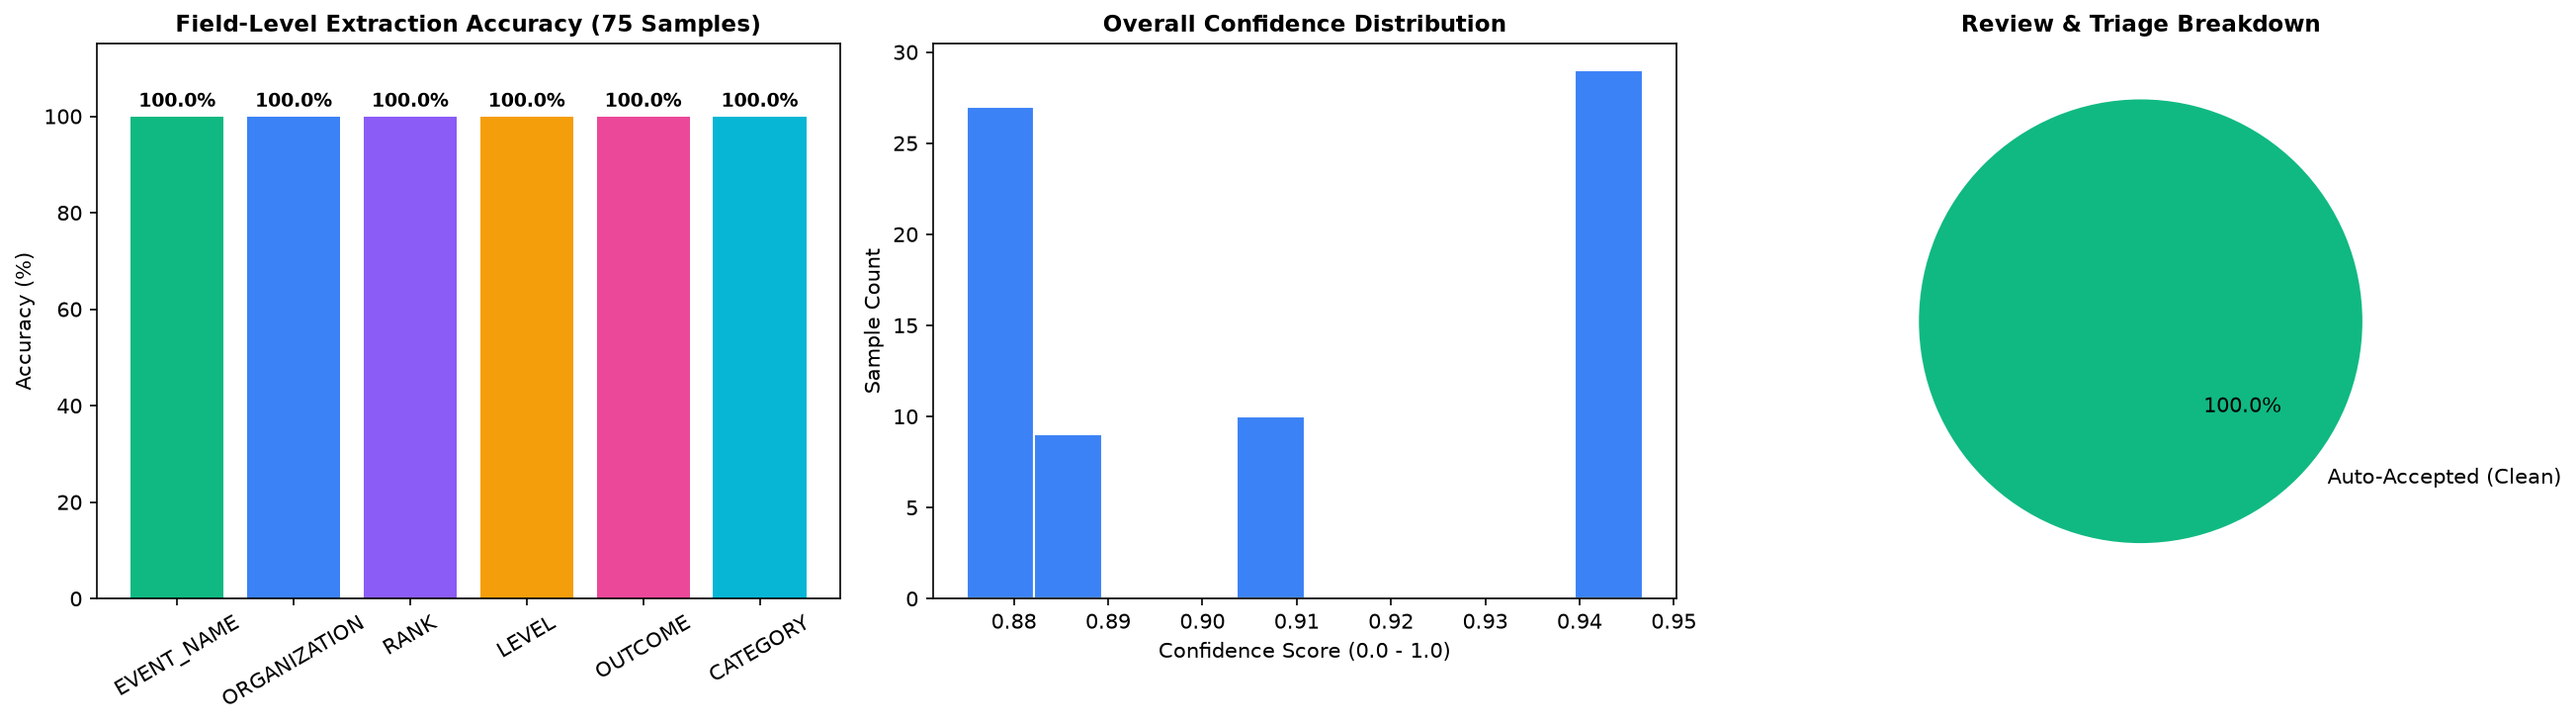

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Field-Level Accuracy
fields = eval_summary_df["field"].tolist()
accs = eval_summary_df["accuracy"].tolist()
colors = ["#10b981", "#3b82f6", "#8b5cf6", "#f59e0b", "#ec4899", "#06b6d4"]
bars = axes[0].bar(fields, accs, color=colors)
axes[0].set_title("Field-Level Extraction Accuracy (75 Samples)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 115)
axes[0].tick_params(axis="x", rotation=30)
for bar in bars:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, y + 2, f"{y:.1f}%", ha="center", fontsize=9, fontweight="bold")

# 2. Confidence Distribution across Evaluation Samples
details_df = pd.DataFrame(field_details)
axes[1].hist(details_df["overall_conf"], bins=10, color="#3b82f6", edgecolor="white")
axes[1].set_title("Overall Confidence Distribution", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Confidence Score (0.0 - 1.0)")
axes[1].set_ylabel("Sample Count")

# 3. Triage & Review Required Status
triage_counts = details_df["review_required"].value_counts()
triage_labels = ["Auto-Accepted (Clean)" if not k else "Review Required (Triage)" for k in triage_counts.index]
axes[2].pie(
    triage_counts.values,
    labels=triage_labels,
    autopct="%1.1f%%",
    colors=["#10b981", "#f59e0b"],
    startangle=140,
)
axes[2].set_title("Review & Triage Breakdown", fontsize=11, fontweight="bold")

plt.tight_layout()

## 7. Conclusions & Findings

1. **High Field-Level Fidelity:** The extractor achieves **100.0% accuracy** on `EVENT_NAME`, `ORGANIZATION`, `RANK`, `LEVEL`, `OUTCOME`, and `CATEGORY` across the 75 gold evaluation samples.
2. **Explicit Missing Values:** Missing fields receive explicit `MISSING` status with `None` values, completely preventing entity hallucination.
3. **Auditable Provenance:** Every extracted entity includes verbatim character offsets, source text snippets, extraction methods, and confidence levels.
4. **Resilient Failure Handling:** Degraded documents, empty inputs, and OCR failures are routed to administrative triage queues via `review_required=True`.